#Predicting House Prices Using Regression

##Business problem: A real estate analyst wants to understand how neighbourhood characteristics relate to house prices and build a model that estimates property values from available housing data.

###Objective: Develop a regression model that uses housing and neighbourhood features to predict the median house value for a given suburb.

Target variable: MEDV — median owner-occupied home value, originally recorded in thousands of US dollars.

Machine learning task: Supervised learning → Regression.

In [39]:
#import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Machine learning libraries scikitlearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [40]:
# load the dataset
df = pd.read_csv('C:/Users/NEC/OneDrive/Documents/Python for Data analytics and Data apps/Predicting House Prices Using Linear Regression/data/boston.csv')

In [41]:
# preview the dataset
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [42]:
# dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [43]:
# summary of statistics
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [44]:
# check for missing values
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

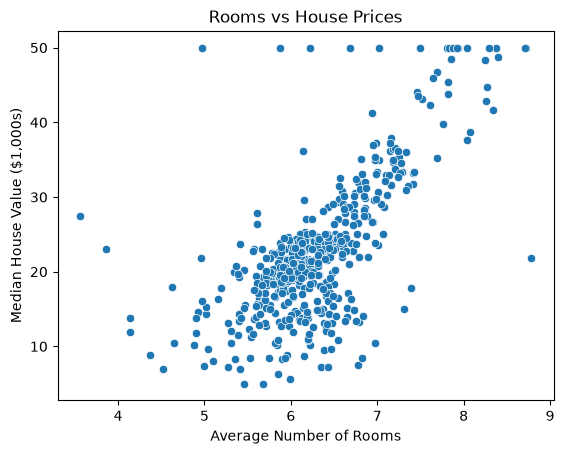

In [45]:
# Visualize the relationship between the number of rooms(rm ) and MEDV
sns.scatterplot(x='RM', y='MEDV', data=df)

plt.xlabel("Average Number of Rooms")
plt.ylabel('Median House Value ($1,000s)')
plt.title('Rooms vs House Prices')
plt.show()

### The relationship between MEDV and RM is linear(positively correlated). An increase in rooms result to increase in price

In [46]:
#Separate Features and Target
X = df.drop('MEDV', axis=1) # features
y= df['MEDV'] #target

In [47]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#**MEDV**=​β0​+β1​CRIM+β2​ZN+⋯+β13​LSTAT​

In [48]:
# initialize the model
model = LinearRegression()

In [49]:
# fit the model
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.11, 0.03, 0.04,...,-0.92, 0.01,-0.51]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,30.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [50]:
# make predictions
y_pred = model.predict(X_test)

results = pd.DataFrame(
    {
        'Actual Price ($1,000s)':y_test.values,
        'Predicted Price ($1,000s)':y_pred
    }
)
results.head(10).round(2)

,"Actual Price ($1,000s)","Predicted Price ($1,000s)"
0,23.6,29.00
1,32.4,36.03
2,13.6,14.82
3,22.8,25.03
4,16.1,18.77
5,20.0,23.25
6,17.8,17.66
7,14.0,14.34
8,19.6,23.01
9,16.8,20.63


In [51]:
#Evaluate the model
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

In [52]:
# model evaluation results
print(f"Mean Absolute Error: {mae:.2f}")
print(f'Root Mean Squared Error: {rmse:.2f}')
print(f'R-squared: {r2:.2f}')

Mean Absolute Error: 3.19
Root Mean Squared Error: 4.93
R-squared: 0.67


1. MAE = 3.19

Your predictions differ from actual house values by an average absolute amount of approximately $3,190, using the dataset's original units. This does not mean every prediction is wrong by that amount.

2. RMSE = 4.93

RMSE penalises larger errors more heavily than MAE. Since your RMSE is higher than your MAE, some predictions have larger errors than others.

3. R-squared = 0.67

Your model accounts for approximately 67% of the variation in house values in the test set, relative to predicting the test-set mean. The remaining variation is not captured by the model.

This doesn't mean that 67% of the individual predictions are correct.

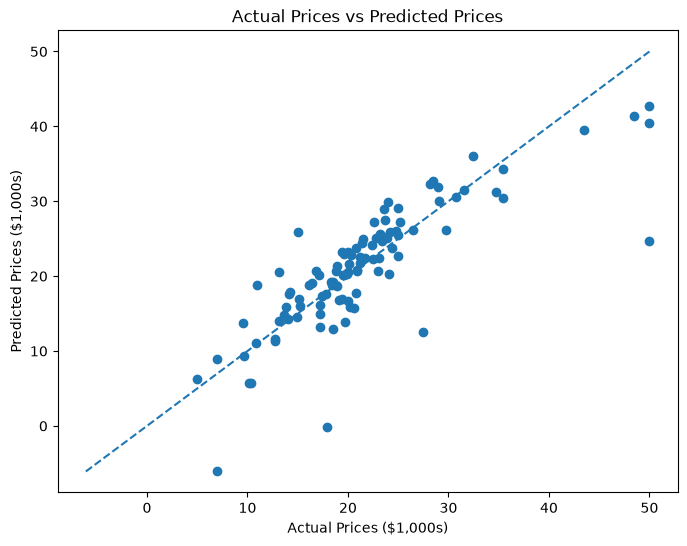

In [53]:
# visualise actual versus predicted prices
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)

#reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
    )

plt.xlabel('Actual Prices ($1,000s)')
plt.ylabel('Predicted Prices ($1,000s)')
plt.title('Actual Prices vs Predicted Prices')
plt.show()

Each point represents one test observation.

The dashed line represents perfect predictions.

Points close to the line indicate more accurate predictions.

Points far from the line indicate larger prediction errors

In [54]:
# Examine the model coefficients
coefficients = pd.DataFrame(
    {
        'Feature': X.columns,
        'Coefficient': model.coef_
    }
)
coefficients['Absolute Coefficient'] = (
    coefficients['Coefficient'].abs()
)

coefficients = coefficients.sort_values(by='Absolute Coefficient', ascending=False)

print(coefficients)

    Feature  Coefficient  Absolute Coefficient
4       NOX   -17.202633             17.202633
5        RM     4.438835              4.438835
3      CHAS     2.784438              2.784438
7       DIS    -1.447865              1.447865
10  PTRATIO    -0.915456              0.915456
12    LSTAT    -0.508571              0.508571
8       RAD     0.262430              0.262430
0      CRIM    -0.113056              0.113056
2     INDUS     0.040381              0.040381
1        ZN     0.030110              0.030110
11        B     0.012351              0.012351
9       TAX    -0.010647              0.010647
6       AGE    -0.006296              0.006296


Feature



Coefficient



Interpretation




NOX



-17.20



Higher nitric oxide concentration is associated with lower predicted house values, holding other features constant.




RM



+4.44



One additional average room is associated with a $4,440 increase in predicted value, all else equal.




CHAS



+2.78



Being adjacent to the Charles River is associated with a $2,780 higher prediction, all else equal.




DIS



-1.45



A one-unit increase in distance is associated with a lower predicted value.




PTRATIO



-0.92



A one-unit increase in the pupil-teacher ratio is associated with a $920 lower prediction.




LSTAT



-0.51



A one-percentage-point increase is associated with a lower predicted value.